# Predicting Heatmaps in Malmö using a CNN

In [ ]:

from pathlib import Path
import random
import numpy as np
import rasterio
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras import layers, models, callbacks


In [2]:

import sys
import subprocess
from pathlib import Path

REPO_URL = "https://github.com/Chardes01/BERN02.git"
REPO_DIR = Path("BERN02")

# Clone only if the repository doesn't exist yet
if not REPO_DIR.exists():
    subprocess.run(
        ["git", "clone", REPO_URL, str(REPO_DIR)],
        check=True,
    )
else:
    # Update the existing repository
    subprocess.run(
        ["git", "-C", str(REPO_DIR), "pull", "--ff-only"],
        check=True,
    )

DATA = REPO_DIR / "final_project" / "data" / "processed_5m"

if not DATA.exists():
    raise FileNotFoundError(
        f"Folder not found: {DATA.resolve()}"
    )

print("Data folder:", DATA.resolve())

for file in sorted(DATA.iterdir()):
    print(file.name)


Data folder: /content/BERN02/final_project/data/processed_5m
01_geographic_split.png
02_training_curves.png
03_validation_diagnostics.png
04_holdout_CNN_prediction.tif
04_holdout_CNN_prediction_best_model.tif
04_holdout_prediction_display_interpolated.tif
04_holdout_spatial_maps_clear.png
best_tuned_cnn.keras
best_tuned_cnn_normalization.npz
future_adjusted
input
outputs_full
target
tuning
tuning_results.txt
visualizations


# Spatial Hold Out Evaluation

## UTCI Prediction — Present-Day Summer Conditions

## Objective

Evaluate the CNN’s ability to predict daytime Universal Thermal Climate Index (UTCI) for a normal summer day in a geographically unseen area of Malmö. A large rectangular region is reserved for validation, while training patches are sampled from outside the held-out region and its surrounding buffer. This experiment assesses spatial generalization rather than performance on randomly mixed locations.

**Test case:** `02_2022-06-24_PRESENT`  
**Scenario:** Typical summer day under present-day conditions  
**Spatial resolution:** 5 m × 5 m

## Input Data

- **Target:** Mean daytime UTCI raster at 5 m spatial resolution.
- **Building presence:** Spatial distribution of buildings.
- **Tree canopy:** Distribution of tree cover.
- **Land use:** Raster layers representing different land-use categories.

All predictor rasters must match the target raster in dimensions, coordinate reference system (CRS), and geospatial transform.

## Geographic Train–Validation Split

The study area is divided geographically using a predefined rectangular validation window:

- **Validation rows:** 20–80% of the raster height.
- **Validation columns:** 65–95% of the raster width.
- **Training exclusion buffer:** 32 pixels around the held-out region.
- **Training patches:** Up to 5,000.
- **Validation patches:** Up to 3,000.
- **Patch size:** 32 × 32 pixels.

Candidate patch centres are sampled on a coarse grid, and patches are retained only when at least 90% of their target pixels are valid. The target value at each patch centre is used as the prediction target.

## CNN Architecture and Training

The CNN learns local spatial relationships between building presence, tree canopy, land use, and UTCI using 32 × 32 pixel input patches.

The architecture consists of:
- Two convolutional layers with 32 filters.
- Max pooling.
- Two convolutional layers with 64 filters.
- Max pooling.
- Two convolutional layers with 96 filters.
- A flattening layer and a dense layer with 128 neurons.
- A 20% dropout layer and a single-output regression layer.

**Training configuration:**
- **Optimizer:** Adam.
- **Learning rate:** 0.0003.
- **Loss function:** Mean Squared Error (MSE).
- **Training metric:** Mean Absolute Error (MAE).
- **Maximum epochs:** 30.
- **Batch size:** 32.
- **Early stopping:** Patience of 5 epochs, restoring the best validation weights.
- **Learning-rate adjustment:** Reduce the learning rate when validation loss stops improving.
- **Target normalization:** Standardization using the training target mean and standard deviation only.

## Evaluation Metrics

Predictions are compared with the reference UTCI values for the geographically held-out patches.

- **MAE:** Average absolute difference between predicted and reference UTCI.
- **RMSE:** Root mean squared error, which gives greater weight to larger errors.
- **Mean bias:** Average signed error, indicating systematic overprediction or underprediction.
- **Mean baseline MAE:** Error from predicting the training-set mean UTCI for every validation sample.

The baseline provides a simple reference for determining whether the CNN improves on a constant prediction.

## Visualizations and Outputs

Three figures are generated:

1. **Geographic validation split** (`01_geographic_split.png`) — displays the UTCI raster and the held-out validation rectangle.
2. **Training curves** (`02_training_curves.png`) — compares training and validation loss and MAE across epochs.
3. **Validation diagnostics** (`03_validation_diagnostics.png`) — compares predicted and reference UTCI values and shows the distribution of prediction errors.

## Purpose

This experiment measures how well the CNN transfers its learned spatial relationships to an unseen part of Malmö. The geographic split, exclusion buffer, performance metrics, and diagnostic figures help assess spatial generalization and identify systematic prediction errors.

**Interpretation:** Strong validation performance suggests that the CNN captures spatial relationships that transfer beyond the training area. However, the result applies to the selected geographic holdout and does not, by itself, establish generalization to other cities, climate scenarios, or time periods.

1. Data Visualization

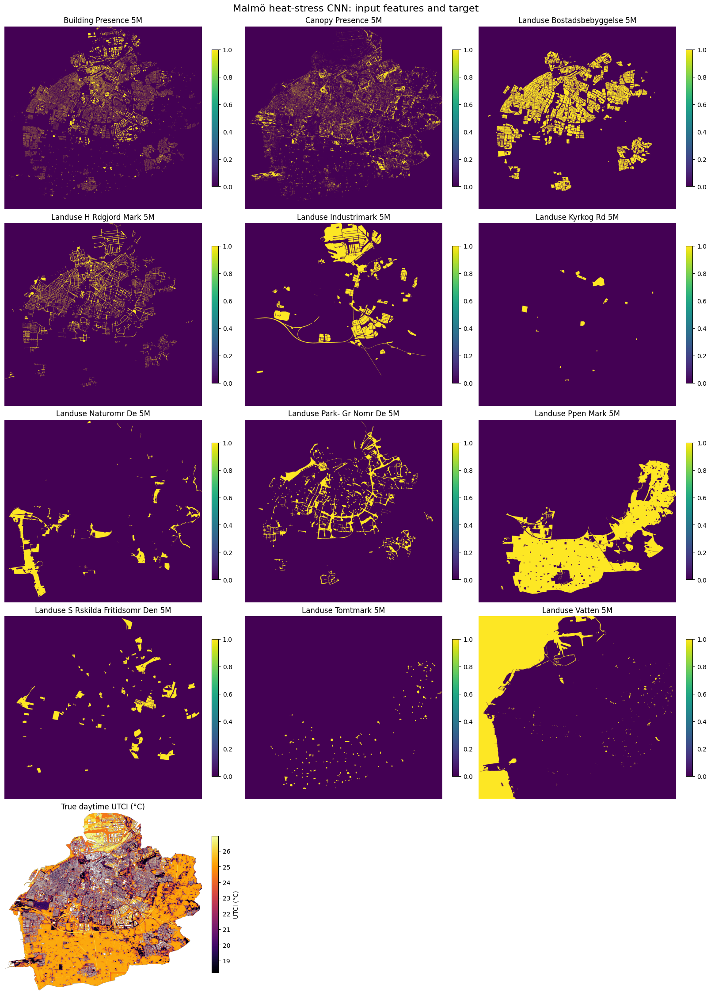

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import math


# --------------------------------------------------
# 1. Overview: input features and true UTCI
# --------------------------------------------------

feature_paths = [
    DATA / "input" / "building_presence_5m.tif",
    DATA / "input" / "canopy_presence_5m.tif",
]

feature_paths += sorted(DATA.glob("input/landuse_*_5m.tif"))
feature_names = [
    p.stem.replace("_10m", "").replace("_", " ").title()
    for p in feature_paths
]

n_features = X.shape[-1]
ncols = 3
nrows = math.ceil((n_features + 1) / ncols)

fig, axes = plt.subplots(
    nrows, ncols, figsize=(16, 4.5 * nrows), constrained_layout=True
)
axes = np.asarray(axes).ravel()

# Input feature maps
for i in range(n_features):
    im = axes[i].imshow(X[:, :, i], cmap="viridis")
    axes[i].set_title(feature_names[i])
    axes[i].set_axis_off()
    fig.colorbar(im, ax=axes[i], shrink=0.75)

# True target
ax = axes[n_features]
target_map = np.where(valid, y, np.nan)
im = ax.imshow(target_map, cmap="inferno")
ax.set_title("True daytime UTCI (°C)")
ax.set_axis_off()
fig.colorbar(im, ax=ax, shrink=0.75, label="UTCI (°C)")

# Hide unused axes
for ax in axes[n_features + 1:]:
    ax.set_visible(False)

fig.suptitle("Malmö heat-stress CNN: input features and target", fontsize=16)
plt.show()



2. Model Training

Raster dimensions: 3124 x 3374
Input channels: 12
Valid target pixels: 5537908
Validation window: rows 624:2499, columns 2193:3205
Approximate dimensions: 18.8 km × 10.1 km
Training patches: 2306
Validation patches: 1004


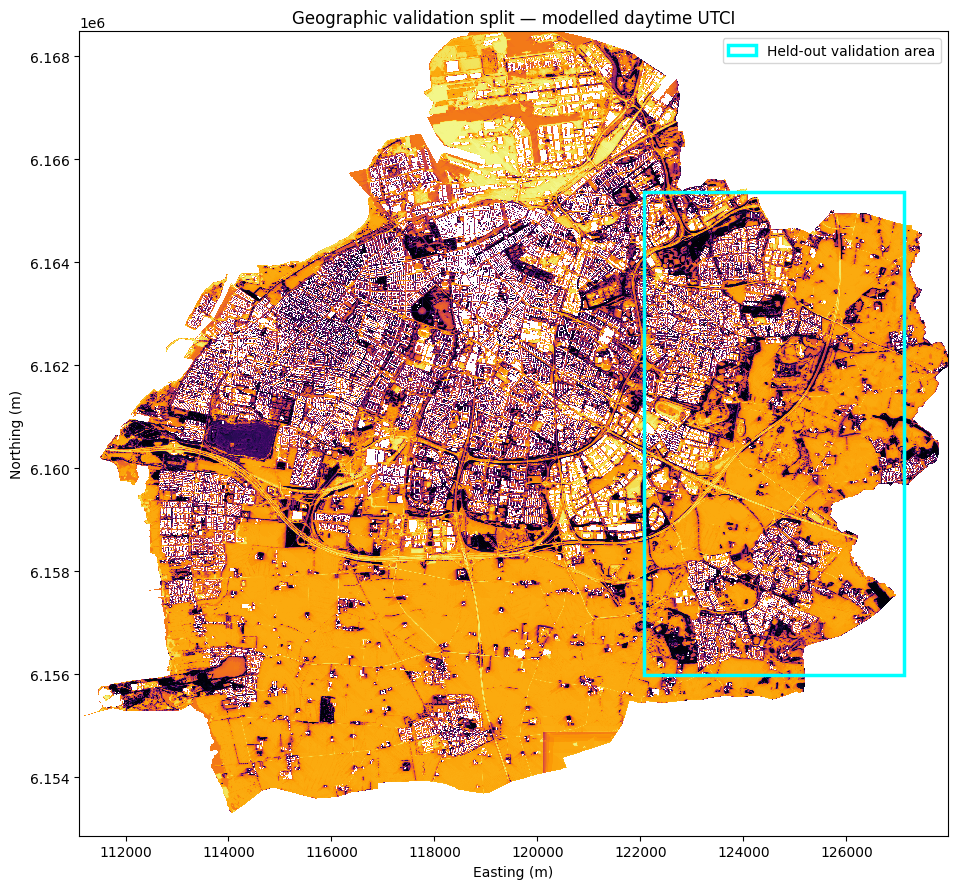

Training UTCI mean: 24.199
Training UTCI std:  2.037
Epoch 1/30
73/73 ━━━━━━━━━━━━━━━━━━━━ 22s 264ms/step - loss: 0.5785 - mae: 0.5157 - val_loss: 0.3576 - val_mae: 0.4324 - learning_rate: 3.0000e-04
Epoch 2/30
73/73 ━━━━━━━━━━━━━━━━━━━━ 19s 259ms/step - loss: 0.3524 - mae: 0.3627 - val_loss: 0.3470 - val_mae: 0.3830 - learning_rate: 3.0000e-04
Epoch 3/30
73/73 ━━━━━━━━━━━━━━━━━━━━ 17s 236ms/step - loss: 0.2855 - mae: 0.3185 - val_loss: 0.3604 - val_mae: 0.3722 - learning_rate: 3.0000e-04
Epoch 4/30
73/73 ━━━━━━━━━━━━━━━━━━━━ 21s 248ms/step - loss: 0.2482 - mae: 0.2932 - val_loss: 0.2982 - val_mae: 0.3279 - learning_rate: 3.0000e-04
Epoch 5/30
73/73 ━━━━━━━━━━━━━━━━━━━━ 20s 234ms/step - loss: 0.2264 - mae: 0.2798 - val_loss: 0.3534 - val_mae: 0.3764 - learning_rate: 3.0000e-04
Epoch 6/30
73/73 ━━━━━━━━━━━━━━━━━━━━ 22s 256ms/step - loss: 0.2093 - mae: 0.2705 - val_loss: 0.3559 - val_mae: 0.3585 - learning_rate: 3.0000e-04
Epoch 7/30
73/73 ━━━━━━━━━━━━━━━━━━━━ 17s 234ms/step - loss: 0.19

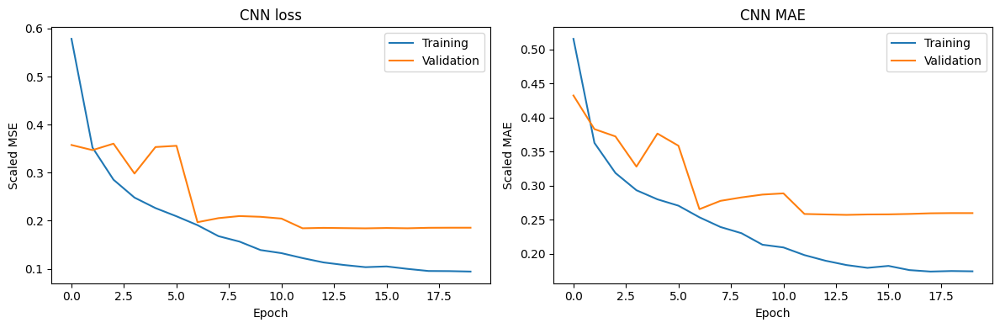

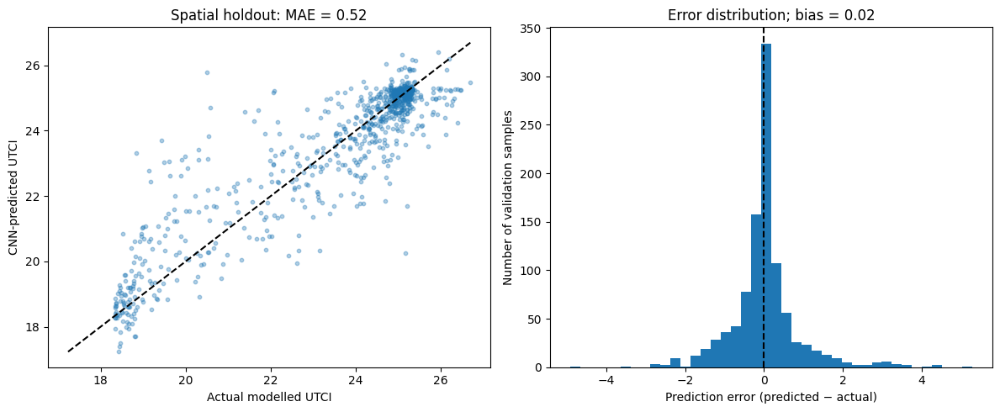

In [19]:

# ==================================================
# 3. Geographic holdout: reserve a large area
# ==================================================
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from sklearn.metrics import mean_absolute_error, mean_squared_error

PATCH = 32
HALF = PATCH // 2
BATCH_SIZE = 32
EPOCHS = 30
TRAIN_PATCHES = 5000
VAL_PATCHES = 3000
CANDIDATE_STRIDE = 32
MAP_STRIDE = 24
SEED = 42

# --------------------------------------------------
target_path = DATA / "target" / "utci_mean_5m_malmo_boundary.tif"

feature_paths = [
    DATA / "input" / "building_presence_5m.tif",
    DATA / "input" / "canopy_presence_5m.tif",
]
feature_paths += sorted(DATA.glob("input/landuse_*_5m.tif"))

if not target_path.exists():
    raise FileNotFoundError(f"Missing target: {target_path}")

if len(feature_paths) < 3:
    raise FileNotFoundError(
        "Expected building, canopy, and land-use rasters in processed/."
    )

with rasterio.open(target_path) as src:
    y = src.read(1).astype(np.float32)
    transform = src.transform
    target_crs = src.crs
    target_nodata = src.nodata
    height, width = y.shape
    target_profile = src.profile.copy()

feature_arrays = []
for path in feature_paths:
    with rasterio.open(path) as src:
        if (
            src.shape != (height, width)
            or src.crs != target_crs
            or not src.transform.almost_equals(transform)
        ):
            raise ValueError(f"Raster grid does not match target: {path.name}")

        feature_arrays.append(src.read(1).astype(np.float32))


# Shape: rows x columns x channels
X = np.stack(feature_arrays, axis=-1)
del feature_arrays

valid = np.isfinite(y)
if target_nodata is not None:
    valid &= y != target_nodata

valid &= np.all(np.isfinite(X), axis=-1)

print("Raster dimensions:", height, "x", width)
print("Input channels:", X.shape[-1])
print("Valid target pixels:", int(valid.sum()))

rng = np.random.default_rng(SEED)

# Adjust these fractions to move/resize the held-out region.
# The validation rectangle covers rows 20–80% and columns 65–95%.
VAL_ROW_START, VAL_ROW_END = 0.20, 0.80
VAL_COL_START, VAL_COL_END = 0.65, 0.95

val_r0 = int(height * VAL_ROW_START)
val_r1 = int(height * VAL_ROW_END)
val_c0 = int(width * VAL_COL_START)
val_c1 = int(width * VAL_COL_END)

print(
    "Validation window:",
    f"rows {val_r0}:{val_r1}, columns {val_c0}:{val_c1}"
)
print(
    "Approximate dimensions:",
    f"{(val_r1-val_r0)*10/1000:.1f} km × "
    f"{(val_c1-val_c0)*10/1000:.1f} km"
)

# Training patch centres must be outside the held-out area,
# with a buffer so training patches cannot overlap it.
BUFFER = PATCH

def in_validation(r, c):
    return val_r0 <= r < val_r1 and val_c0 <= c < val_c1

def in_training(r, c):
    # Exclude the validation rectangle and a surrounding buffer.
    return not (
        val_r0 - BUFFER <= r < val_r1 + BUFFER
        and val_c0 - BUFFER <= c < val_c1 + BUFFER
    )

# ==================================================
# 4. Sample spatially separated patch centres
# ==================================================
# Check that each patch contains enough valid target pixels.
# Candidate centres are sampled on a coarse grid for speed.

def get_centres(region_fn, n_wanted, seed_offset=0):
    candidates = []

    for r in range(HALF, height - HALF, CANDIDATE_STRIDE):
        for c in range(HALF, width - HALF, CANDIDATE_STRIDE):
            if region_fn(r, c):
                candidates.append((r, c))

    local_rng = np.random.default_rng(SEED + seed_offset)
    local_rng.shuffle(candidates)

    chosen = []
    for r, c in candidates:
        r0, r1 = r - HALF, r - HALF + PATCH
        c0, c1 = c - HALF, c - HALF + PATCH

        if not valid[r, c]:
            continue

        if valid[r0:r1, c0:c1].mean() < 0.90:
            continue

        chosen.append((r, c))
        if len(chosen) >= n_wanted:
            break

    return chosen

train_centres = get_centres(in_training, TRAIN_PATCHES, 1)
val_centres = get_centres(in_validation, VAL_PATCHES, 2)

if len(train_centres) < 100 or len(val_centres) < 30:
    raise ValueError(
        f"Not enough valid patches: train={len(train_centres)}, "
        f"validation={len(val_centres)}. Try moving/resizing the "
        "validation rectangle or inspect target validity."
    )

print("Training patches:", len(train_centres))
print("Validation patches:", len(val_centres))

# ==================================================
# 5. Visualize the geographic split
# ==================================================
# Show the whole raster and the held-out rectangle.
# Coordinates are in the target raster's projected CRS.

left = transform.c
top = transform.f
right = left + width * transform.a
bottom = top + height * transform.e
extent = [left, right, bottom, top]

fig, ax = plt.subplots(figsize=(10, 9))
ax.imshow(
    np.ma.masked_where(~valid, y),
    extent=extent,
    origin="upper",
    cmap="inferno",
    interpolation="nearest"
)

# Convert row/column window to map coordinates.
x0 = left + val_c0 * transform.a
x1 = left + val_c1 * transform.a
y0 = top + val_r0 * transform.e
y1 = top + val_r1 * transform.e

rect = Rectangle(
    (min(x0, x1), min(y0, y1)),
    abs(x1 - x0),
    abs(y1 - y0),
    fill=False,
    edgecolor="cyan",
    linewidth=2.5,
    label="Held-out validation area"
)
ax.add_patch(rect)
ax.set_title("Geographic validation split — modelled daytime UTCI")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.legend()
plt.tight_layout()
plt.savefig(DATA / "01_geographic_split.png", dpi=200)
plt.show()

# ==================================================
# 6. Extract training and validation patches
# ==================================================
def make_patches(centres):
    Xp = np.empty(
        (len(centres), PATCH, PATCH, X.shape[-1]),
        dtype=np.float32
    )
    yp = np.empty(len(centres), dtype=np.float32)

    for i, (r, c) in enumerate(centres):
        Xp[i] = X[
            r-HALF:r-HALF+PATCH,
            c-HALF:c-HALF+PATCH,
            :
        ]
        yp[i] = y[r, c]

    return Xp, yp

X_train, y_train = make_patches(train_centres)
X_val, y_val = make_patches(val_centres)

# Normalize the target using training data only.
y_mean = float(y_train.mean())
y_std = float(y_train.std())

if y_std == 0:
    raise ValueError("Training target has zero variance.")

y_train_scaled = (y_train - y_mean) / y_std
y_val_scaled = (y_val - y_mean) / y_std

print(f"Training UTCI mean: {y_mean:.3f}")
print(f"Training UTCI std:  {y_std:.3f}")

# ==================================================
# 7. Define and train CNN
# ==================================================
tf.keras.utils.set_random_seed(SEED)


model = models.Sequential([
    layers.Input(shape=(PATCH, PATCH, X.shape[-1])),

    # Preserve local spatial information
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),

    layers.Conv2D(96, 3, padding="same", activation="relu"),
    layers.Conv2D(96, 3, padding="same", activation="relu"),

    # Keep a spatial feature map until the final prediction
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(1),
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=3e-4),
    loss="mse",
    metrics=["mae"],
)

#model.summary()


early_stop = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

history = model.fit(
    X_train,
    y_train_scaled,
    validation_data=(X_val, y_val_scaled),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

# ==================================================
# 8. Evaluate on the held-out area
# ==================================================
pred_scaled = model.predict(
    X_val, batch_size=BATCH_SIZE, verbose=0
).ravel()

pred = pred_scaled * y_std + y_mean

mae = mean_absolute_error(y_val, pred)
rmse = np.sqrt(mean_squared_error(y_val, pred))
bias = float(np.mean(pred - y_val))

baseline = np.full_like(y_val, y_mean)
baseline_mae = mean_absolute_error(y_val, baseline)

print("\nHELD-OUT GEOGRAPHIC VALIDATION")
print(f"MAE:           {mae:.3f} UTCI units")
print(f"RMSE:          {rmse:.3f} UTCI units")
print(f"Mean bias:     {bias:.3f} UTCI units")
print(f"Mean baseline: {baseline_mae:.3f} UTCI units")

# ==================================================
# 9. Training curves
# ==================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["loss"], label="Training")
axes[0].plot(history.history["val_loss"], label="Validation")
axes[0].set_title("CNN loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Scaled MSE")
axes[0].legend()

axes[1].plot(history.history["mae"], label="Training")
axes[1].plot(history.history["val_mae"], label="Validation")
axes[1].set_title("CNN MAE")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Scaled MAE")
axes[1].legend()

plt.tight_layout()
plt.savefig(DATA / "02_training_curves.png", dpi=200)
plt.show()

# ==================================================
# 10. Actual vs prediction and error distribution
# ==================================================
errors = pred - y_val

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(y_val, pred, s=10, alpha=0.35)
vmin = min(float(y_val.min()), float(pred.min()))
vmax = max(float(y_val.max()), float(pred.max()))
axes[0].plot([vmin, vmax], [vmin, vmax], "k--")
axes[0].set_xlabel("Actual modelled UTCI")
axes[0].set_ylabel("CNN-predicted UTCI")
axes[0].set_title(f"Spatial holdout: MAE = {mae:.2f}")

axes[1].hist(errors, bins=40)
axes[1].axvline(0, color="black", linestyle="--")
axes[1].set_xlabel("Prediction error (predicted − actual)")
axes[1].set_ylabel("Number of validation samples")
axes[1].set_title(f"Error distribution; bias = {bias:.2f}")

plt.tight_layout()
plt.savefig(DATA / "03_validation_diagnostics.png", dpi=200)
plt.show()




3. Prediction for the hold-out area

Holdout shape: (1875, 1012)
Valid target pixels: 1492382
Prediction locations: 1492382
MAP_STRIDE: 1
Batch size: 1024
Predicted 1,024 / 1,492,382 locations
Predicted 11,264 / 1,492,382 locations
Predicted 21,504 / 1,492,382 locations
Predicted 31,744 / 1,492,382 locations
Predicted 41,984 / 1,492,382 locations
Predicted 52,224 / 1,492,382 locations
Predicted 62,464 / 1,492,382 locations
Predicted 72,704 / 1,492,382 locations
Predicted 82,944 / 1,492,382 locations
Predicted 93,184 / 1,492,382 locations
Predicted 103,424 / 1,492,382 locations
Predicted 113,664 / 1,492,382 locations
Predicted 123,904 / 1,492,382 locations
Predicted 134,144 / 1,492,382 locations
Predicted 144,384 / 1,492,382 locations
Predicted 154,624 / 1,492,382 locations
Predicted 164,864 / 1,492,382 locations
Predicted 175,104 / 1,492,382 locations
Predicted 185,344 / 1,492,382 locations
Predicted 195,584 / 1,492,382 locations
Predicted 205,824 / 1,492,382 locations
Predicted 216,064 / 1,492,382 locations
Predicted 226

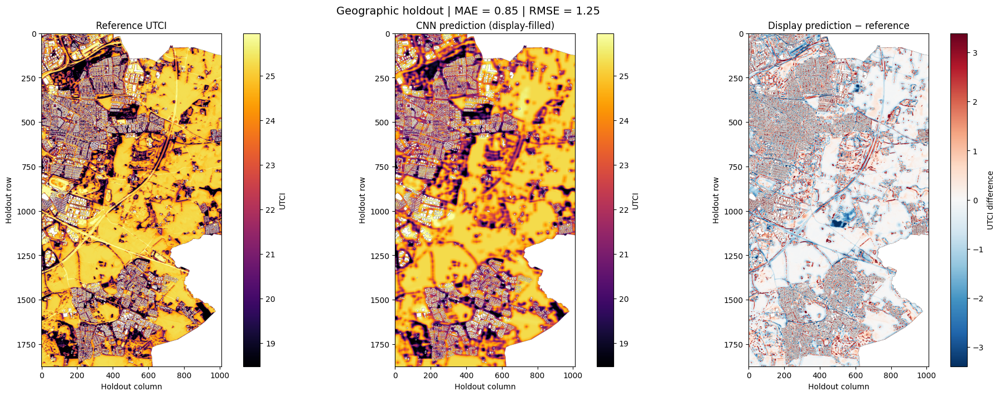


Actual prediction GeoTIFF
CRS: EPSG:3008
Bounds: BoundingBox(left=122065.0, bottom=6155985.0, right=127125.0, top=6165360.0)
Resolution: (5.0, 5.0)
Dimensions: 1012 x 1875
NoData: -9999.0

Done.


In [11]:

# ============================================================
# 11. Optimized geographic holdout prediction + GeoTIFF export
# ============================================================

import time
from pathlib import Path

import numpy as np
import rasterio
import tensorflow as tf
import matplotlib.pyplot as plt

from scipy.ndimage import distance_transform_edt


# ------------------------------------------------------------
# 1. Settings
# ------------------------------------------------------------

REPO_DATA = Path(DATA)

# Try 256 first; increase to 512 or 1024 if memory permits.
BATCH_SIZE = 1024

# Use 1 for predictions at every eligible pixel.
# Use 4 for a quicker, sparse prediction map.
MAP_STRIDE = 1

NODATA = -9999.0

# IMPORTANT: replace with the path to your original aligned
# UTCI GeoTIFF, which has the correct CRS and grid.
reference_tif =  DATA / "utci_mean_10m_malmo_boundary.tif"

# Output files
output_tif = REPO_DATA / "04_holdout_CNN_prediction_best_model.tif"
display_tif = REPO_DATA / "04_holdout_prediction_display_interpolated.tif"


# ------------------------------------------------------------
# 2. Holdout bounds
# ------------------------------------------------------------

r0, r1 = int(val_r0), int(val_r1)
c0, c1 = int(val_c0), int(val_c1)

assert 0 <= r0 < r1 <= height, "Invalid holdout row bounds"
assert 0 <= c0 < c1 <= width, "Invalid holdout column bounds"

actual = y[r0:r1, c0:c1].astype(np.float32, copy=True)
valid_crop = valid[r0:r1, c0:c1].astype(bool)

actual[~valid_crop] = np.nan

if not np.isfinite(actual).any():
    raise ValueError("No valid target pixels in the holdout area.")

print("Holdout shape:", actual.shape)
print("Valid target pixels:", int(np.isfinite(actual).sum()))


# ------------------------------------------------------------
# 3. Find eligible prediction centres
# ------------------------------------------------------------

patch_half = PATCH // 2

# These ranges ensure patches fit inside the full feature grid.
centres = [
    (r, c)
    for r in range(
        max(r0, patch_half),
        min(r1, height - (PATCH - patch_half) + 1),
        MAP_STRIDE
    )
    for c in range(
        max(c0, patch_half),
        min(c1, width - (PATCH - patch_half) + 1),
        MAP_STRIDE
    )
    if valid[r, c]
]

print("Prediction locations:", len(centres))
print("MAP_STRIDE:", MAP_STRIDE)
print("Batch size:", BATCH_SIZE)

if not centres:
    raise ValueError("No eligible prediction centres found.")


# ------------------------------------------------------------
# 4. Predict in batches
# ------------------------------------------------------------

pred_crop = np.full(actual.shape, np.nan, dtype=np.float32)

# Use direct model calls to avoid repeated predict() wrapper overhead.
start_time = time.time()
patch_indices = np.arange(PATCH)

for start in range(0, len(centres), BATCH_SIZE):
    batch_centres = centres[start:start + BATCH_SIZE]

    # Extract only the current batch of patches.
    batch_X = np.stack([
        X[
            r - patch_half:r - patch_half + PATCH,
            c - patch_half:c - patch_half + PATCH,
            :
        ]
        for r, c in batch_centres
    ]).astype(np.float32, copy=False)

    # CNN inference
    predictions = model(batch_X, training=False).numpy().reshape(-1)

    # Convert standardized outputs back to UTCI units.
    predictions = predictions * y_std + y_mean

    # Vectorized assignment into the cropped holdout array.
    rr = np.fromiter(
        (r - r0 for r, c in batch_centres),
        dtype=np.intp,
        count=len(batch_centres)
    )
    cc = np.fromiter(
        (c - c0 for r, c in batch_centres),
        dtype=np.intp,
        count=len(batch_centres)
    )

    pred_crop[rr, cc] = predictions.astype(np.float32)

    if start == 0 or (start // BATCH_SIZE) % 10 == 0:
        print(
            f"Predicted {min(start + len(batch_centres), len(centres)):,}"
            f" / {len(centres):,} locations"
        )

elapsed = time.time() - start_time
print(f"Prediction time: {elapsed / 60:.1f} minutes")
print("Actual prediction pixels:", int(np.isfinite(pred_crop).sum()))


# ------------------------------------------------------------
# 5. Calculate metrics on actual predictions only
# ------------------------------------------------------------

scored = np.isfinite(actual) & np.isfinite(pred_crop)

if scored.any():
    errors = pred_crop[scored] - actual[scored]
    mae_holdout = float(np.mean(np.abs(errors)))
    rmse_holdout = float(np.sqrt(np.mean(errors ** 2)))

    print(f"Holdout MAE:  {mae_holdout:.3f}")
    print(f"Holdout RMSE: {rmse_holdout:.3f}")
else:
    mae_holdout = np.nan
    rmse_holdout = np.nan
    print("No overlapping target and prediction pixels for metrics.")


# ------------------------------------------------------------
# 6. Get the correct georeferencing
# ------------------------------------------------------------

with rasterio.open(reference_tif) as src:
    profile = src.profile.copy()
    original_transform = src.transform
    original_crs = src.crs

# Shift the full-grid transform to the holdout's top-left pixel.
holdout_transform = (
    original_transform * rasterio.Affine.translation(c0, r0)
)

print("CRS:", original_crs)
print("Holdout transform:", holdout_transform)


# ------------------------------------------------------------
# 7. Save actual CNN predictions as GeoTIFF
# ------------------------------------------------------------

def save_geotiff(array, path, base_profile, affine_transform):
    """Save a 2D float array as a georeferenced GeoTIFF."""
    output = np.where(
        np.isfinite(array),
        array,
        NODATA
    ).astype(np.float32)

    out_profile = base_profile.copy()
    out_profile.update(
        driver="GTiff",
        height=array.shape[0],
        width=array.shape[1],
        count=1,
        dtype="float32",
        crs=original_crs,
        transform=affine_transform,
        nodata=NODATA,
        compress="lzw"
    )

    # Remove inherited tiling settings that may be invalid for
    # small crops or incompatible with the source profile.
    out_profile.pop("blockxsize", None)
    out_profile.pop("blockysize", None)

    with rasterio.open(path, "w", **out_profile) as dst:
        dst.write(output, 1)

    print("Saved:", path)


save_geotiff(
    pred_crop,
    output_tif,
    profile,
    holdout_transform
)


# ------------------------------------------------------------
# 8. Optional: create a continuous-looking display raster
# ------------------------------------------------------------
# Nearest-neighbour filling is for visualization only.
# It does NOT create additional CNN predictions.

display_input = pred_crop.copy()

# Do not fill invalid target pixels.
display_input[~np.isfinite(actual)] = np.nan

known = np.isfinite(display_input)

if known.any():
    # Find nearest valid sampled prediction for each display cell.
    nearest_indices = distance_transform_edt(
        ~known,
        return_distances=False,
        return_indices=True
    )

    prediction_display = display_input[
        tuple(nearest_indices)
    ].astype(np.float32)

    # Keep cells with invalid target data blank.
    prediction_display[~np.isfinite(actual)] = np.nan

    save_geotiff(
        prediction_display,
        display_tif,
        profile,
        holdout_transform
    )
else:
    prediction_display = np.full_like(pred_crop, np.nan)
    print("No valid predictions to interpolate for display.")


# ------------------------------------------------------------
# 9. Plot the maps
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(19, 7), constrained_layout=True)

valid_actual = actual[np.isfinite(actual)]
vmin, vmax = np.percentile(valid_actual, [2, 98])

im0 = axes[0].imshow(
    actual,
    cmap="inferno",
    vmin=vmin,
    vmax=vmax,
    origin="upper"
)
axes[0].set_title("Reference UTCI")
fig.colorbar(im0, ax=axes[0], label="UTCI")

im1 = axes[1].imshow(
    prediction_display,
    cmap="inferno",
    vmin=vmin,
    vmax=vmax,
    origin="upper"
)
axes[1].set_title("CNN prediction (display-filled)")
fig.colorbar(im1, ax=axes[1], label="UTCI")

error_display = prediction_display - actual
finite_errors = error_display[np.isfinite(error_display)]

if finite_errors.size:
    err_lim = max(
        float(np.percentile(np.abs(finite_errors), 98)),
        0.1
    )
else:
    err_lim = 1.0

im2 = axes[2].imshow(
    error_display,
    cmap="RdBu_r",
    vmin=-err_lim,
    vmax=err_lim,
    origin="upper"
)
axes[2].set_title("Display prediction − reference")
fig.colorbar(im2, ax=axes[2], label="UTCI difference")

for ax in axes:
    ax.set_aspect("equal")
    ax.set_xlabel("Holdout column")
    ax.set_ylabel("Holdout row")

fig.suptitle(
    f"Geographic holdout | MAE = {mae_holdout:.2f} | "
    f"RMSE = {rmse_holdout:.2f}",
    fontsize=14
)

fig.savefig(
    REPO_DATA / "04_holdout_spatial_maps_clear.png",
    dpi=250,
    bbox_inches="tight"
)
plt.show()


# ------------------------------------------------------------
# 10. Verify saved GeoTIFF
# ------------------------------------------------------------

with rasterio.open(output_tif) as src:
    print("\nActual prediction GeoTIFF")
    print("CRS:", src.crs)
    print("Bounds:", src.bounds)
    print("Resolution:", src.res)
    print("Dimensions:", src.width, "x", src.height)
    print("NoData:", src.nodata)

print("\nDone.")


4. Visualization of the prediction and actual area

## CNN Hyperparameter Tuning

Hyperparameter tuning was performed using **Keras Tuner Random Search**, evaluating up to 20 CNN configurations to minimize internal validation MAE.

The search explored the number of convolutional blocks, filter counts, kernel sizes, L2 regularization, dense layer size, dropout rate, and learning rate. Early stopping and learning-rate reduction were used to improve training efficiency and reduce overfitting.

To limit spatial leakage, training patches were split into fitting and internal validation sets based on geographic blocks. The best-performing configuration was then evaluated on the independent geographic holdout.

The optimized model, normalization parameters, selected hyperparameters, and evaluation results were saved for reproducibility.

In [9]:
%pip install -q keras-tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 3.9 MB/s eta 0:00:00


In [ ]:

# ==================================================
# 6. Extract patches and create internal spatial split
# ==================================================
import keras_tuner as kt
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models, callbacks, regularizers
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error

tf.keras.utils.set_random_seed(SEED)

def make_patches(centres):
    Xp = np.empty(
        (len(centres), PATCH, PATCH, X.shape[-1]),
        dtype=np.float32
    )
    yp = np.empty(len(centres), dtype=np.float32)

    for i, (r, c) in enumerate(centres):
        Xp[i] = X[r-HALF:r-HALF+PATCH, c-HALF:c-HALF+PATCH, :]
        yp[i] = y[r, c]

    return Xp, yp

# Extract training-region patches and final geographic holdout patches
X_train_all, y_train_all = make_patches(train_centres)
X_test, y_test = make_patches(val_centres)

# Group training patches by their spatial block.
# This prevents nearby patches from being split randomly across
# fitting and internal validation sets.
TUNE_BLOCK_SIZE = 128  # cells = 1.28 km at 10 m resolution
n_block_cols = int(np.ceil(width / TUNE_BLOCK_SIZE))

train_groups = np.array([
    (r // TUNE_BLOCK_SIZE) * n_block_cols + c // TUNE_BLOCK_SIZE
    for r, c in train_centres
])

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=SEED
)

fit_idx, tune_idx = next(
    splitter.split(X_train_all, y_train_all, groups=train_groups)
)

X_fit, X_tune = X_train_all[fit_idx], X_train_all[tune_idx]
y_fit_raw, y_tune_raw = y_train_all[fit_idx], y_train_all[tune_idx]

print("Fitting patches:", len(fit_idx))
print("Internal spatial validation patches:", len(tune_idx))
print("Final geographic holdout patches:", len(X_test))
print("Fit blocks:", len(set(train_groups[fit_idx])))
print("Tuning blocks:", len(set(train_groups[tune_idx])))

if len(fit_idx) < 100 or len(tune_idx) < 30:
    raise ValueError(
        "Too few patches in the internal spatial split. "
        "Try a smaller TUNE_BLOCK_SIZE or collect more training patches."
    )

# Normalize the target using fitting data only.
y_mean = float(y_fit_raw.mean())
y_std = float(y_fit_raw.std())

if y_std == 0:
    raise ValueError("Training target has zero variance.")

y_fit = (y_fit_raw - y_mean) / y_std
y_tune = (y_tune_raw - y_mean) / y_std

# Keep the geographic holdout in original UTCI units.
# Scale it only for model prediction comparison if needed.
y_test_scaled = (y_test - y_mean) / y_std

print(f"Fitting UTCI mean: {y_mean:.3f}")
print(f"Fitting UTCI std:  {y_std:.3f}")


# ==================================================
# 7. Define tunable CNN architecture
# ==================================================
def build_model(hp):
    inputs = layers.Input(shape=(PATCH, PATCH, X.shape[-1]))
    z = inputs

    n_blocks = hp.Choice("n_blocks", [2, 3])

    kernel_size = hp.Choice("kernel_size", [3, 5])
    l2_strength = hp.Choice("l2_strength", [1e-5, 1e-4, 1e-3])

    for block in range(n_blocks):
        filters = hp.Choice(
            f"filters_{block}",
            [16, 32, 64]
        )

        z = layers.Conv2D(
            filters,
            kernel_size,
            padding="same",
            activation="relu",
            kernel_regularizer=regularizers.l2(l2_strength)
        )(z)

        z = layers.Conv2D(
            filters,
            3,
            padding="same",
            activation="relu"
        )(z)

        if block < n_blocks - 1:
            z = layers.MaxPooling2D(2)(z)

    z = layers.GlobalAveragePooling2D()(z)

    dense_units = hp.Choice("dense_units", [32, 64, 128])
    z = layers.Dense(dense_units, activation="relu")(z)

    dropout = hp.Choice("dropout", [0.0, 0.2, 0.35])
    z = layers.Dropout(dropout)(z)

    outputs = layers.Dense(1)(z)

    model = models.Model(inputs, outputs)

    lr = hp.Choice("learning_rate", [1e-4, 3e-4, 1e-3])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss="mse",
        metrics=["mae"]
    )
    return model


# ==================================================
# 8. Hyperparameter search
# ==================================================
tuner = kt.RandomSearch(
    build_model,
    objective=kt.Objective("val_mae", direction="min"),
    max_trials=20,
    executions_per_trial=1,
    directory=str(DATA / "tuning"),
    project_name="malmo_utci",
    overwrite=True,
    seed=SEED
)

tuner_callbacks = [
    callbacks.EarlyStopping(
        monitor="val_mae",
        mode="min",
        patience=5,
        restore_best_weights=True
    ),
    callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    )
]

tuner.search(
    X_fit,
    y_fit,
    validation_data=(X_tune, y_tune),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=tuner_callbacks,
    verbose=1
)

best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
best_model = tuner.get_best_models(num_models=1)[0]

print("\nBEST HYPERPARAMETERS")
for name, value in best_hp.values.items():
    print(f"{name}: {value}")

best_model.summary()

# The tuning-selected model has not seen the final geographic holdout.
# Its weights are restored from the best internal validation epoch.


# ==================================================
# 9. Final evaluation on geographic holdout
# ==================================================
pred_scaled = best_model.predict(
    X_test,
    batch_size=BATCH_SIZE,
    verbose=0
).ravel()

pred = pred_scaled * y_std + y_mean

mae = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))
bias = float(np.mean(pred - y_test))

baseline = np.full_like(y_test, y_mean)
baseline_mae = mean_absolute_error(y_test, baseline)

print("\nFINAL GEOGRAPHIC HOLDOUT")
print(f"MAE:           {mae:.3f} UTCI units")
print(f"RMSE:          {rmse:.3f} UTCI units")
print(f"Mean bias:     {bias:.3f} UTCI units")
print(f"Mean baseline: {baseline_mae:.3f} UTCI units")


# ==================================================
# 10. Plot tuning and holdout diagnostics
# ==================================================
# Plot the best trial's recorded tuning curve.
best_trial = tuner.oracle.get_best_trials(num_trials=1)[0]
trial_history = best_trial.metrics.get_history("val_mae")

if trial_history:
    val_mae_curve = [item.value[0] for item in trial_history]
    plt.figure(figsize=(7, 4))
    plt.plot(range(1, len(val_mae_curve) + 1), val_mae_curve)
    plt.xlabel("Epoch")
    plt.ylabel("Internal validation MAE (scaled)")
    plt.title("Best trial: validation learning curve")
    plt.tight_layout()
    plt.savefig(DATA / "02_tuning_curve.png", dpi=200)
    plt.show()

errors = pred - y_test

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(y_test, pred, s=10, alpha=0.35)
lo = min(float(y_test.min()), float(pred.min()))
hi = max(float(y_test.max()), float(pred.max()))
axes[0].plot([lo, hi], [lo, hi], "k--")
axes[0].set_xlabel("Actual modelled UTCI")
axes[0].set_ylabel("Predicted UTCI")
axes[0].set_title(f"Geographic holdout: MAE = {mae:.2f}")

axes[1].hist(errors, bins=40)
axes[1].axvline(0, color="black", linestyle="--")
axes[1].set_xlabel("Prediction error")
axes[1].set_ylabel("Number of samples")
axes[1].set_title(f"Error distribution: bias = {bias:.2f}")

plt.tight_layout()
plt.savefig(DATA / "03_validation_diagnostics.png", dpi=200)
plt.show()


# ==================================================
# 11. Save model, normalization, and results
# ==================================================
best_model.save(DATA / "best_tuned_cnn.keras")

np.savez(
    DATA / "best_tuned_cnn_normalization.npz",
    y_mean=y_mean,
    y_std=y_std
)

with open(DATA / "tuning_results.txt", "w") as f:
    f.write("Geographic holdout evaluation\n")
    f.write(f"Holdout rows: {val_r0}:{val_r1}\n")
    f.write(f"Holdout columns: {val_c0}:{val_c1}\n")
    f.write(f"Training patches available: {len(train_centres)}\n")
    f.write(f"Final holdout patches: {len(val_centres)}\n")
    f.write(f"MAE: {mae:.4f}\n")
    f.write(f"RMSE: {rmse:.4f}\n")
    f.write(f"Bias: {bias:.4f}\n")
    f.write(f"Mean baseline MAE: {baseline_mae:.4f}\n")
    f.write("\nBest hyperparameters:\n")
    for name, value in best_hp.values.items():
        f.write(f"{name}: {value}\n")

print("Saved tuned model and results to:", DATA.resolve())


# Climate Scenario Left-Out — Leave-One-Scenario-Out Evaluation

### Objective
Evaluate how well the CNN generalizes to unseen climate scenarios by performing a **10-fold leave-one-scenario-out experiment**. In each fold, the model is trained on nine scenarios and evaluated on the remaining scenario, which is excluded from training and validation.

### Input Data
All raster inputs are aligned to a common reference grid at 5 m spatial resolution.

- **Static predictors:** building presence, tree canopy, and 10 land-use classes.
- **Dynamic predictor:** scenario-specific air temperature raster.
- **Target:** scenario-specific UTCI (Universal Thermal Climate Index) raster.

The experiment includes 10 present-day and future climate scenarios covering hot and normal summer conditions, the RCP4.5 and RCP8.5 pathways, and projections for 2050 and 2100.

### Model Architecture and Training
The CNN uses 9 × 9 pixel patches to learn local spatial relationships between the input features and UTCI. Its architecture consists of convolutional layers with 32, 64, and 96 filters, max-pooling, a dense layer with 128 neurons, and 20% dropout.

- **Training samples:** up to 3,000 valid pixels per training scenario.
- **Optimizer:** Adam, with a learning rate of 0.0003.
- **Loss function:** Mean Squared Error (MSE).
- **Evaluation metric during training:** Mean Absolute Error (MAE).
- **Training duration:** up to 25 epochs.
- **Early stopping:** patience of 4 epochs, monitoring validation loss.
- **Normalization:** predictor and target statistics are calculated using training data only.

A 15% validation split is used for early stopping and model checkpoint selection. The held-out scenario is loaded for evaluation only after training is complete.

### Prediction and Evaluation
For each held-out scenario, the trained model predicts UTCI at valid pixel locations. Predictions are compared with the corresponding reference UTCI raster using three metrics:

- **MAE:** average absolute prediction error.
- **RMSE:** root mean squared prediction error, which penalizes larger errors more strongly.
- **Bias:** mean signed error, indicating systematic overprediction or underprediction.

The workflow generates georeferenced UTCI prediction rasters and error maps for each fold, alongside a summary CSV containing the evaluation metrics.

### Outputs
Results are saved under `outputs/climate_scenario_holdout/`:

- `predictions/` — predicted UTCI GeoTIFFs for all 10 held-out scenarios.
- `error_maps/` — spatial error GeoTIFFs for all 10 scenarios.
- `leave_one_scenario_out_metrics.csv` — summary of MAE, RMSE, bias, and valid test pixel counts.
- Scenario-specific subfolders — best model checkpoints and normalization parameters for reproducibility.

### Purpose
This experiment assesses the model's ability to transfer across climate conditions and future scenarios rather than simply reproducing patterns from scenarios represented during training. The resulting metrics and spatial error maps help identify scenarios where UTCI predictions generalize well or exhibit larger errors.

1. Model training

In [33]:

from pathlib import Path
import gc
import json
import numpy as np
import pandas as pd
import rasterio
from rasterio.warp import reproject, Resampling
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import os

# ============================================================
# 1. CONFIGURATION
# ============================================================


INPUT_DIR = DATA / "input"
TARGET_DIR = DATA / "target"  # Contains the 10 masked UTCI scenario rasters
TEMPERATURE_DIR = DATA / "future_adjusted"

OUT_DIR = DATA / "outputs_full" / "scenario_holdout"
PRED_DIR = OUT_DIR / "predictions"
ERROR_DIR = OUT_DIR / "error_maps"

for p in [OUT_DIR, PRED_DIR, ERROR_DIR]:
    p.mkdir(parents=True, exist_ok=True)

STATIC_FILES = [
    "building_presence_5m.tif",
    "canopy_presence_5m.tif",
    "landuse_bostadsbebyggelse_5m.tif",
    "landuse_h_rdgjord_mark_5m.tif",
    "landuse_industrimark_5m.tif",
    "landuse_kyrkog_rd_5m.tif",
    "landuse_naturomr_de_5m.tif",
    "landuse_park-_gr_nomr_de_5m.tif",
    "landuse_ppen_mark_5m.tif",
    "landuse_s_rskilda_fritidsomr_den_5m.tif",
    "landuse_tomtmark_5m.tif",
    "landuse_vatten_5m.tif",
]

# TARGET_DIR contains the scenario-specific UTCI files listed in SCENARIOS.

SCENARIOS = {
    "01_present_hot": {
        "target": "1994-07-26_UTCI_present_hot_5m_malmo_boundary.tif",
        "temperature": "1994-07-26_temperature_C.tif",
    },
    "02_current_normal": {
        "target": "2022-06-24_UTCI_current_5m_malmo_boundary.tif",
        "temperature": "2022-06-24_temperature_C.tif",
    },
    "03_rcp85_2050_hot": {
        "target": "1994-07-26_UTCI_RCP85_2050_5m_malmo_boundary.tif",
        "temperature": "1994-07-26_temperature_RCP85_2050.tif",
    },
    "04_rcp85_2100_hot": {
        "target": "1994-07-26_UTCI_RCP85_2100_5m_malmo_boundary.tif",
        "temperature": "1994-07-26_temperature_RCP85_2100.tif",
    },
    "05_rcp45_2050_hot": {
        "target": "1994-07-26_UTCI_RCP45_2050_5m_malmo_boundary.tif",
        "temperature": "1994-07-26_temperature_RCP45_2050.tif",
    },
    "06_rcp45_2100_hot": {
        "target": "1994-07-26_UTCI_RCP45_2100_5m_malmo_boundary.tif",
        "temperature": "1994-07-26_temperature_RCP45_2100.tif",
    },
    "07_rcp85_2050_normal": {
        "target": "2022-06-24_UTCI_RCP85_2050_5m_malmo_boundary.tif",
        "temperature": "2022-06-24_temperature_RCP85_2050.tif",
    },
    "08_rcp85_2100_normal": {
        "target": "2022-06-24_UTCI_RCP85_2100_5m_malmo_boundary.tif",
        "temperature": "2022-06-24_temperature_RCP85_2100.tif",
    },
    "09_rcp45_2050_normal": {
        "target": "2022-06-24_UTCI_RCP45_2050_5m_malmo_boundary.tif",
        "temperature": "2022-06-24_temperature_RCP45_2050.tif",
    },
    "10_rcp45_2100_normal": {
        "target": "2022-06-24_UTCI_RCP45_2100_5m_malmo_boundary.tif",
        "temperature": "2022-06-24_temperature_RCP45_2100.tif",
    },
}

# Fail early if a configured input file is missing.
for scenario_name, cfg in SCENARIOS.items():
    target_path = TARGET_DIR / cfg["target"]
    temperature_path = TEMPERATURE_DIR / cfg["temperature"]
    if not target_path.is_file():
        raise FileNotFoundError(
            f"Missing UTCI target for {scenario_name}: {target_path}"
        )
    if not temperature_path.is_file():
        raise FileNotFoundError(
            f"Missing temperature raster for {scenario_name}: {temperature_path}"
        )

for static_name in STATIC_FILES:
    static_path = INPUT_DIR / static_name
    if not static_path.is_file():
        raise FileNotFoundError(f"Missing static raster: {static_path}")

PATCH = 9
HALF = PATCH // 2

# Samples per training scenario in each fold.
SAMPLES_PER_SCENARIO = 3000

BATCH_SIZE = 128
EPOCHS = 25
PREDICT_STRIDE = 1  # Use 1 for every pixel; 4 samples every 4th pixel.
SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)

# ============================================================
# 2. SET THE REFERENCE GRID
# ============================================================

first_name = next(iter(SCENARIOS))
reference_path = TARGET_DIR / SCENARIOS[first_name]["target"]

if not reference_path.exists():
    raise FileNotFoundError(
        f"Reference UTCI raster not found: {reference_path}"
    )

with rasterio.open(reference_path) as src:
    if src.crs is None:
        raise ValueError(
            f"Reference raster has no CRS: {reference_path}"
        )

    REF_PROFILE = src.profile.copy()
    REF_CRS = src.crs
    REF_TRANSFORM = src.transform
    HEIGHT, WIDTH = src.height, src.width

print("Reference raster:", reference_path.name)
print("Grid:", WIDTH, "x", HEIGHT)
print("CRS:", REF_CRS)
print(
    "Pixel size:",
    REF_TRANSFORM.a,
    REF_TRANSFORM.e
)


# ============================================================
# 3. READ AND ALIGN RASTERS
# ============================================================

def read_aligned(path, categorical=False):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"Raster not found: {path}")

    with rasterio.open(path) as src:
        if src.crs is None:
            raise ValueError(f"Raster has no CRS: {path}")

        source = src.read(1, masked=True).astype(np.float32)
        source = source.filled(np.nan)

        destination = np.full(
            (HEIGHT, WIDTH), np.nan, dtype=np.float32
        )

        reproject(
            source=source,
            destination=destination,
            src_transform=src.transform,
            src_crs=src.crs,
            src_nodata=np.nan,
            dst_transform=REF_TRANSFORM,
            dst_crs=REF_CRS,
            dst_nodata=np.nan,
            resampling=(
                Resampling.nearest
                if categorical
                else Resampling.bilinear
            ),
        )

    return destination



def load_static():
    """Load static predictors while preserving meaningful zero values."""
    arrays = []

    for filename in STATIC_FILES:
        path = os.path.join(INPUT_DIR, filename)

        with rasterio.open(path) as src:
            arr = src.read(1).astype(np.float32)

            # Only convert actual non-finite values to NaN.
            # Do NOT mask zero when zero means feature absence.
            arr[~np.isfinite(arr)] = np.nan

            # Preserve other declared NoData values, but not zero.
            if src.nodata is not None and src.nodata != 0:
                arr[arr == src.nodata] = np.nan

        arrays.append(arr)

    return np.stack(arrays, axis=0)



STATIC = load_static()
print("Static channels:", STATIC.shape[-1])

# ============================================================
# 4. LOAD ONE SCENARIO AT A TIME
# ============================================================

def load_scenario(scenario_name):
    cfg = SCENARIOS[scenario_name]

    # Each scenario's target is a raster filename, not a folder.
    target_path = TARGET_DIR / cfg["target"]
    temperature_path = TEMPERATURE_DIR / cfg["temperature"]

    temperature = read_aligned(
        temperature_path,
        categorical=False,
    )

    target = read_aligned(
        target_path,
        categorical=False,
    )

    
    features = np.concatenate(
        [np.moveaxis(STATIC, 0, -1), temperature[..., None]],
        axis=-1,
    )


    # Require the complete patch to have valid features.
    valid_features = np.all(np.isfinite(features), axis=-1)
    valid_target = np.isfinite(target)

    return features, target, valid_features & valid_target


def sample_training_patches(features, target, valid, rng):
    # Exclude borders so every sampled point has a complete patch.
    rows, cols = np.where(valid)
    inside = (
        (rows >= HALF)
        & (rows < HEIGHT - HALF)
        & (cols >= HALF)
        & (cols < WIDTH - HALF)
    )
    rows, cols = rows[inside], cols[inside]

    if len(rows) == 0:
        raise ValueError("No valid training pixels for this scenario.")

    n = min(SAMPLES_PER_SCENARIO, len(rows))
    chosen = rng.choice(len(rows), size=n, replace=False)
    rows, cols = rows[chosen], cols[chosen]

    patches = np.stack([
        features[
            r-HALF:r+HALF+1,
            c-HALF:c+HALF+1,
            :
        ]
        for r, c in zip(rows, cols)
    ]).astype(np.float32)

    values = target[rows, cols].astype(np.float32)

    return patches, values


# ============================================================
# 5. CREATE AND TRAIN THE CNN
# ============================================================

def build_model(n_channels):
    
    model = models.Sequential([
        layers.Input(shape=(PATCH, PATCH,n_channels)),

        # Preserve local spatial information
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(2),

        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(2),

        layers.Conv2D(96, 3, padding="same", activation="relu"),
        layers.Conv2D(96, 3, padding="same", activation="relu"),

        # Keep a spatial feature map until the final prediction
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(1),
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=3e-4),
        loss="mse",
        metrics=["mae"],
    )

    return model


def train_fold(held_out_name, fold_number):
    rng = np.random.default_rng(SEED + fold_number)

    X_parts, y_parts = [], []

    for name in SCENARIOS:
        if name == held_out_name:
            continue

        print("  Sampling training scenario:", name)

        features, target, valid = load_scenario(name)
        X_part, y_part = sample_training_patches(
            features, target, valid, rng
        )

        X_parts.append(X_part)
        y_parts.append(y_part)

        del features, target, valid
        gc.collect()

    X_train = np.concatenate(X_parts, axis=0)
    y_train = np.concatenate(y_parts, axis=0)

    del X_parts, y_parts
    gc.collect()

    # Shuffle across all nine training scenarios before Keras takes
    # validation_split from the final 15% of the arrays. Without this,
    # validation could consist mostly of samples from one scenario.
    permutation = rng.permutation(len(X_train))
    X_train = X_train[permutation]
    y_train = y_train[permutation]

    # Compute normalization only from training scenarios.
    channel_mean = X_train.mean(axis=(0, 1, 2))
    channel_std = X_train.std(axis=(0, 1, 2))
    channel_std[channel_std < 1e-6] = 1.0

    X_train = (
        X_train - channel_mean[None, None, None, :]
    ) / channel_std[None, None, None, :]

    y_mean = float(y_train.mean())
    y_std = float(y_train.std())
    if y_std < 1e-6:
        y_std = 1.0

    y_train = (y_train - y_mean) / y_std

    model = build_model(X_train.shape[-1])

    fold_dir = OUT_DIR / held_out_name
    fold_dir.mkdir(parents=True, exist_ok=True)

    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=4,
            restore_best_weights=True,
        ),
        keras.callbacks.ModelCheckpoint(
            fold_dir / "best_model.keras",
            monitor="val_loss",
            save_best_only=True,
        ),
    ]

    # Validation is drawn ONLY from the nine training scenarios.
    # The held-out scenario's target is never used here.
    model.fit(
        X_train,
        y_train,
        validation_split=0.15,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=callbacks,
        verbose=1,
        shuffle=True,
    )

    np.savez(
        fold_dir / "normalization.npz",
        channel_mean=channel_mean,
        channel_std=channel_std,
        y_mean=y_mean,
        y_std=y_std,
    )

    del X_train, y_train
    gc.collect()

    return model, channel_mean, channel_std, y_mean, y_std


# ============================================================
# 6. PREDICT THE HELD-OUT SCENARIO
# ============================================================

def write_geotiff(path, array):
    profile = REF_PROFILE.copy()
    profile.update(
        driver="GTiff",
        height=HEIGHT,
        width=WIDTH,
        count=1,
        dtype="float32",
        nodata=-9999.0,
        compress="deflate",
    )

    output = np.where(
        np.isfinite(array), array, -9999.0
    ).astype(np.float32)

    with rasterio.open(path, "w", **profile) as dst:
        dst.write(output, 1)


def predict_scenario(
    model, features, valid,
    channel_mean, channel_std, y_mean, y_std,
):
    pred = np.full((HEIGHT, WIDTH), np.nan, dtype=np.float32)

    # Only predict pixels with complete patches.
    valid_centres = valid.copy()
    valid_centres[:HALF, :] = False
    valid_centres[-HALF:, :] = False
    valid_centres[:, :HALF] = False
    valid_centres[:, -HALF:] = False

    # Sampling stride reduces computation. Metrics apply only
    # to the locations that actually receive predictions.
    rows, cols = np.where(valid_centres)

    # Keep only every PREDICT_STRIDE-th row and column.
    keep = (
        (rows % PREDICT_STRIDE == 0)
        & (cols % PREDICT_STRIDE == 0)
    )
    rows, cols = rows[keep], cols[keep]

    for start in range(0, len(rows), 512):
        rr = rows[start:start+512]
        cc = cols[start:start+512]

        patches = np.stack([
            features[
                r-HALF:r+HALF+1,
                c-HALF:c+HALF+1,
                :
            ]
            for r, c in zip(rr, cc)
        ]).astype(np.float32)

        patches = (
            patches - channel_mean[None, None, None, :]
        ) / channel_std[None, None, None, :]

        pred_norm = model(
            patches, training=False
        ).numpy().reshape(-1)

        pred[rr, cc] = pred_norm * y_std + y_mean

    return pred


def check_raster(path):
    with rasterio.open(path) as src:
        arr = src.read(1, masked=True).astype(np.float32)
        data = arr.filled(np.nan)

        valid_count = int(np.isfinite(data).sum())

        print(
            f"{Path(path).name}: "
            f"valid={valid_count:,} / {data.size:,}, "
            f"CRS={src.crs}, "
            f"shape={src.shape}, "
            f"nodata={src.nodata}"
        )

# ============================================================
# 7. RUN ALL 10 LEAVE-ONE-SCENARIO-OUT FOLDS
# ============================================================

all_metrics = []

for fold_number, held_out_name in enumerate(SCENARIOS, start=1):
    print("\n" + "=" * 70)
    print(f"FOLD {fold_number}/10 — HELD OUT: {held_out_name}")
    print("=" * 70)

    tf.keras.backend.clear_session()
    gc.collect()
    
# ============================================================
# DIAGNOSTICS: CHECK VALID PIXELS IN EACH INPUT RASTER
# ============================================================



    # print("REFERENCE GRID")
    # check_raster(reference_path)

    # print("\nSTATIC PREDICTORS")
    # for name in STATIC_FILES:
    #     check_raster(INPUT_DIR / name)

    # print("\nSCENARIO TARGETS AND TEMPERATURES")
    # for name, cfg in SCENARIOS.items():
    #     print(f"\n{name}")
    #     check_raster(TARGET_DIR / cfg["target"])
    #     check_raster(TEMPERATURE_DIR / cfg["temperature"])


    model, channel_mean, channel_std, y_mean, y_std = train_fold(
        held_out_name, fold_number
    )

    # Load the held-out scenario only after training finishes.
    test_features, test_target, test_valid = load_scenario(
        held_out_name
    )

    prediction = predict_scenario(
        model,
        test_features,
        test_valid,
        channel_mean,
        channel_std,
        y_mean,
        y_std,
    )

    evaluation = np.isfinite(prediction) & np.isfinite(test_target)
    errors = prediction[evaluation] - test_target[evaluation]

    if errors.size == 0:
        mae = float("nan")
        rmse = float("nan")
        bias = float("nan")
        print(
            f"WARNING: {held_out_name} has no pixels with both "
            "valid predictions and valid target values."
        )
    else:
        mae = float(np.mean(np.abs(errors)))
        rmse = float(np.sqrt(np.mean(errors ** 2)))
        bias = float(np.mean(errors))

    print(
        f"{held_out_name}: "
        f"n={len(errors)}, MAE={mae:.3f}, "
        f"RMSE={rmse:.3f}, bias={bias:.3f}"
    )

    write_geotiff(
        PRED_DIR / f"{held_out_name}_utci_prediction.tif",
        prediction,
    )

    error_map = np.full(
        (HEIGHT, WIDTH), np.nan, dtype=np.float32
    )
    error_map[evaluation] = errors

    write_geotiff(
        ERROR_DIR / f"{held_out_name}_utci_error.tif",
        error_map,
    )

    all_metrics.append({
        "held_out_scenario": held_out_name,
        "n_test_pixels": int(evaluation.sum()),
        "MAE_UTCI": mae,
        "RMSE_UTCI": rmse,
        "Bias_UTCI": bias,
    })

    del model, test_features, test_target, test_valid
    del prediction, error_map
    gc.collect()

    print("Saved predictions and error map.")

# ============================================================
# 8. SAVE SUMMARY TABLE
# ============================================================

metrics_df = pd.DataFrame(all_metrics)
metrics_df.to_csv(
    OUT_DIR / "leave_one_scenario_out_metrics.csv",
    index=False,
)

print("\nFINAL LEAVE-ONE-SCENARIO-OUT RESULTS")
print(metrics_df.to_string(index=False))
print("\nSaved to:", OUT_DIR)

Reference raster: 1994-07-26_UTCI_present_hot_5m_malmo_boundary.tif
Grid: 3374 x 3124
CRS: EPSG:3008
Pixel size: 5.0 -5.0
Static channels: 3374

FOLD 1/10 — HELD OUT: 01_present_hot
  Sampling training scenario: 02_current_normal
  Sampling training scenario: 03_rcp85_2050_hot
  Sampling training scenario: 04_rcp85_2100_hot
  Sampling training scenario: 05_rcp45_2050_hot
  Sampling training scenario: 06_rcp45_2100_hot
  Sampling training scenario: 07_rcp85_2050_normal
  Sampling training scenario: 08_rcp85_2100_normal
  Sampling training scenario: 09_rcp45_2050_normal
  Sampling training scenario: 10_rcp45_2100_normal
Epoch 1/25
180/180 ━━━━━━━━━━━━━━━━━━━━ 15s 42ms/step - loss: 0.1356 - mae: 0.2490 - val_loss: 0.0541 - val_mae: 0.1621
Epoch 2/25
180/180 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0561 - mae: 0.1697 - val_loss: 0.0484 - val_mae: 0.1502
Epoch 3/25
180/180 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0501 - mae: 0.1596 - val_loss: 0.0453 - val_mae: 0.1469
Epoch 4/25
180/180

2. Visualization

01_present_hot: MAE=1.12 °C, RMSE=1.27 °C, bias=-1.01 °C, pixels=5,536,281
02_current_normal: MAE=1.14 °C, RMSE=1.38 °C, bias=-0.88 °C, pixels=5,536,281
03_rcp85_2050_hot: MAE=0.74 °C, RMSE=0.91 °C, bias=-0.54 °C, pixels=5,536,281
04_rcp85_2100_hot: MAE=0.51 °C, RMSE=0.78 °C, bias=0.07 °C, pixels=5,536,281
05_rcp45_2050_hot: MAE=0.55 °C, RMSE=0.80 °C, bias=-0.19 °C, pixels=5,536,281
06_rcp45_2100_hot: MAE=0.50 °C, RMSE=0.76 °C, bias=0.14 °C, pixels=5,536,281
07_rcp85_2050_normal: MAE=0.66 °C, RMSE=0.93 °C, bias=-0.16 °C, pixels=5,536,281
08_rcp85_2100_normal: MAE=1.33 °C, RMSE=1.60 °C, bias=1.30 °C, pixels=5,536,281
09_rcp45_2050_normal: MAE=0.63 °C, RMSE=0.94 °C, bias=0.12 °C, pixels=5,536,281
10_rcp45_2100_normal: MAE=0.62 °C, RMSE=0.94 °C, bias=0.30 °C, pixels=5,536,281


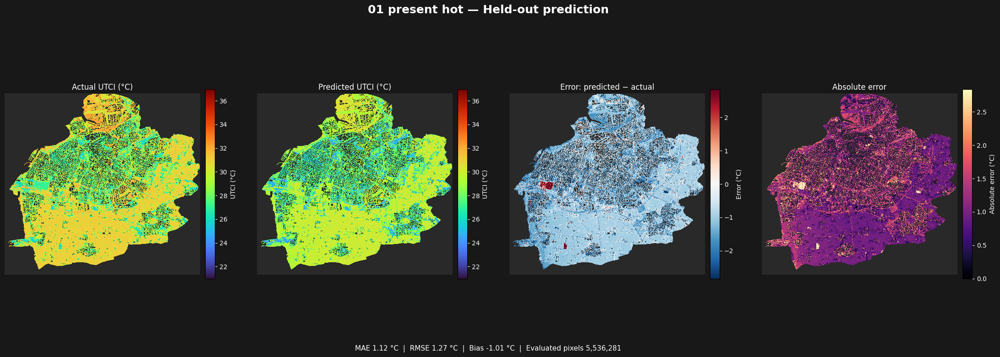

Saved: BERN02/final_project/data/processed_5m/visualizations/01_present_hot_actual_vs_prediction.png


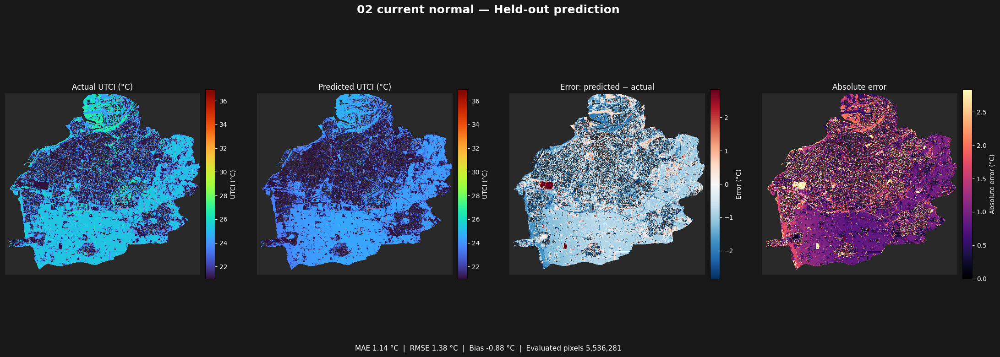

Saved: BERN02/final_project/data/processed_5m/visualizations/02_current_normal_actual_vs_prediction.png


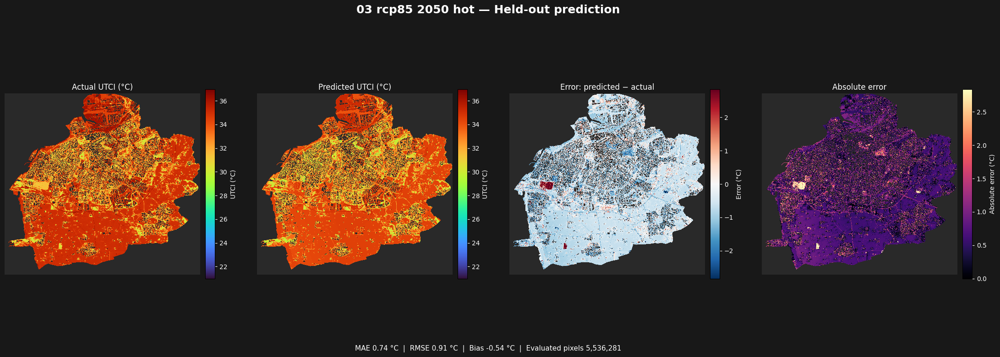

Saved: BERN02/final_project/data/processed_5m/visualizations/03_rcp85_2050_hot_actual_vs_prediction.png


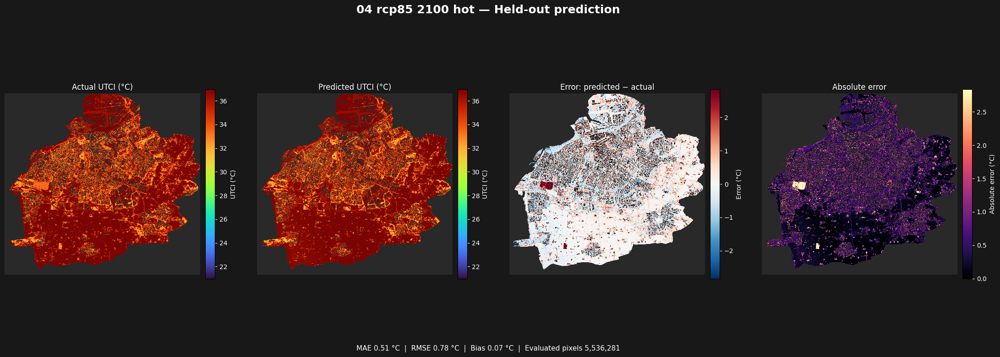

Saved: BERN02/final_project/data/processed_5m/visualizations/04_rcp85_2100_hot_actual_vs_prediction.png


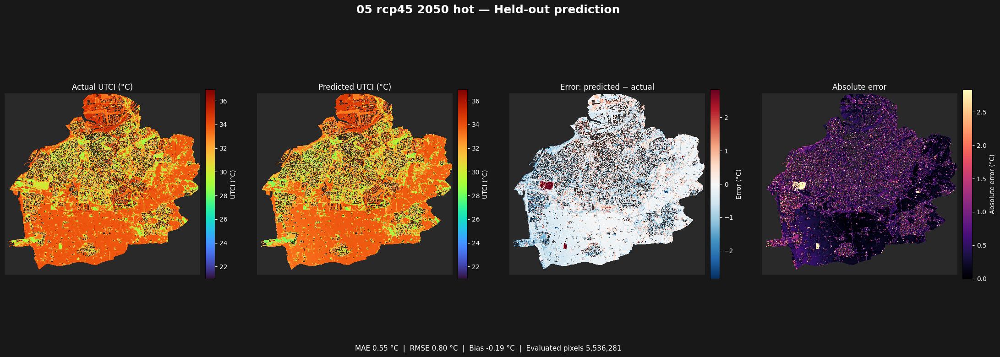

Saved: BERN02/final_project/data/processed_5m/visualizations/05_rcp45_2050_hot_actual_vs_prediction.png


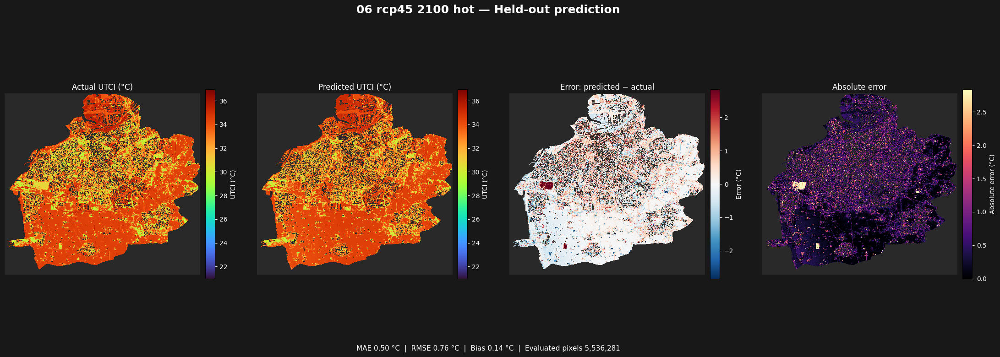

Saved: BERN02/final_project/data/processed_5m/visualizations/06_rcp45_2100_hot_actual_vs_prediction.png


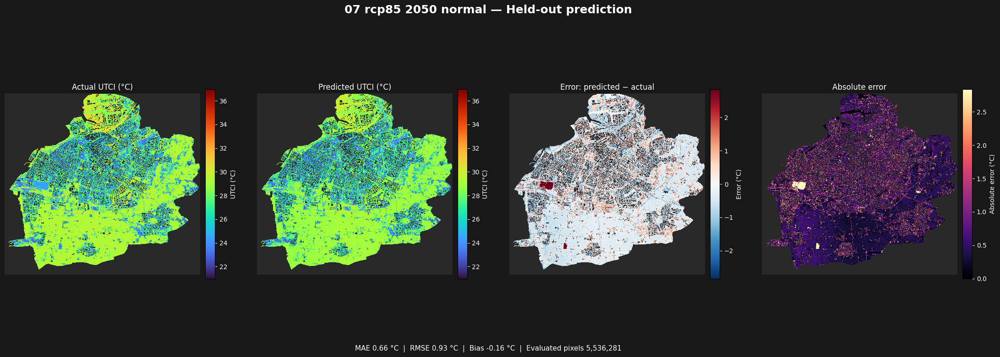

Saved: BERN02/final_project/data/processed_5m/visualizations/07_rcp85_2050_normal_actual_vs_prediction.png


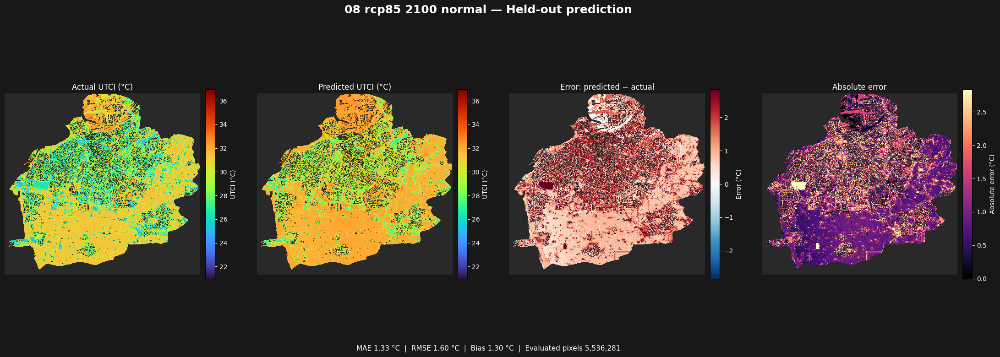

Saved: BERN02/final_project/data/processed_5m/visualizations/08_rcp85_2100_normal_actual_vs_prediction.png


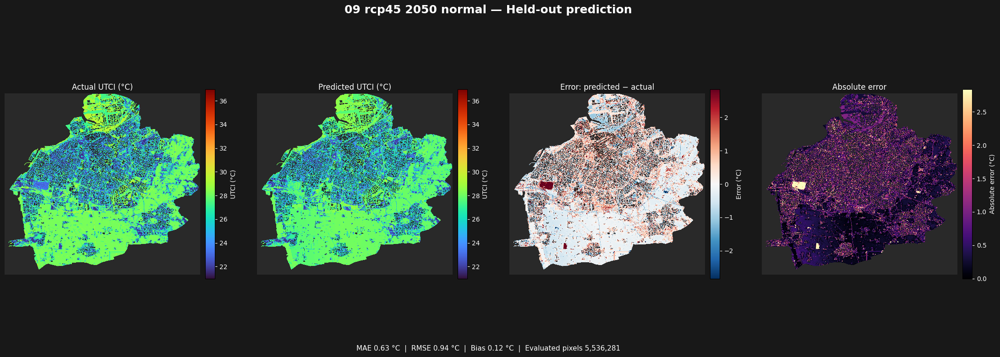

Saved: BERN02/final_project/data/processed_5m/visualizations/09_rcp45_2050_normal_actual_vs_prediction.png


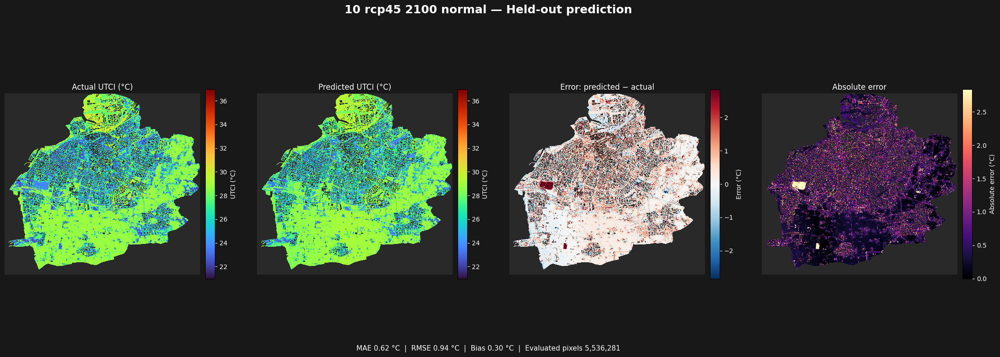

Saved: BERN02/final_project/data/processed_5m/visualizations/10_rcp45_2100_normal_actual_vs_prediction.png


,scenario,valid_pixels,MAE_C,RMSE_C,bias_C
0,01_present_hot,5536281,1.121878,1.269719,-1.008098
1,02_current_normal,5536281,1.140909,1.379495,-0.882436
2,03_rcp85_2050_hot,5536281,0.741453,0.906468,-0.543299
3,04_rcp85_2100_hot,5536281,0.512096,0.784158,0.066993
4,05_rcp45_2050_hot,5536281,0.552066,0.803598,-0.187188
5,06_rcp45_2100_hot,5536281,0.499340,0.756401,0.142521
6,07_rcp85_2050_normal,5536281,0.663070,0.932159,-0.164141
7,08_rcp85_2100_normal,5536281,1.330851,1.601802,1.299596
8,09_rcp45_2050_normal,5536281,0.634114,0.938421,0.115773
9,10_rcp45_2100_normal,5536281,0.620234,0.944240,0.304997


Metrics saved: BERN02/final_project/data/processed_5m/visualizations/held_out_utci_metrics.csv


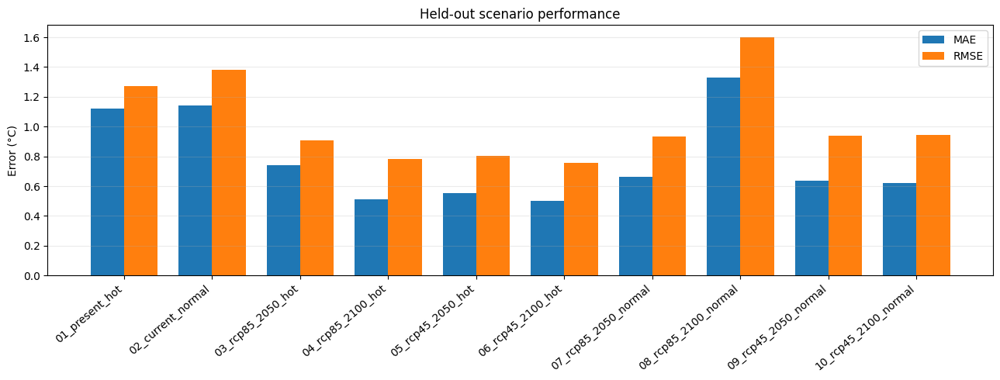

Summary chart saved: BERN02/final_project/data/processed_5m/visualizations/held_out_scenario_metrics.png
All outputs saved in: BERN02/final_project/data/processed_5m/visualizations


In [34]:

from pathlib import Path
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

# ============================================================
# 1. PATHS
# ============================================================


TARGET_DIR = DATA / "target"
PREDICTION_DIR = DATA / "outputs_full" / "scenario_holdout" / "predictions"
FIGURE_DIR = DATA / "visualizations"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Change this if your prediction filenames differ.
def prediction_filename(scenario):
    return f"{scenario}_utci_prediction.tif"


# ============================================================
# 2. SCENARIO FILES
# ============================================================
SCENARIOS = {
    "01_present_hot": "1994-07-26_UTCI_present_hot_5m_malmo_boundary.tif",
    "02_current_normal": "2022-06-24_UTCI_current_5m_malmo_boundary.tif",
    "03_rcp85_2050_hot": "1994-07-26_UTCI_RCP85_2050_5m_malmo_boundary.tif",
    "04_rcp85_2100_hot": "1994-07-26_UTCI_RCP85_2100_5m_malmo_boundary.tif",
    "05_rcp45_2050_hot": "1994-07-26_UTCI_RCP45_2050_5m_malmo_boundary.tif",
    "06_rcp45_2100_hot": "1994-07-26_UTCI_RCP45_2100_5m_malmo_boundary.tif",
    "07_rcp85_2050_normal": "2022-06-24_UTCI_RCP85_2050_5m_malmo_boundary.tif",
    "08_rcp85_2100_normal": "2022-06-24_UTCI_RCP85_2100_5m_malmo_boundary.tif",
    "09_rcp45_2050_normal": "2022-06-24_UTCI_RCP45_2050_5m_malmo_boundary.tif",
    "10_rcp45_2100_normal": "2022-06-24_UTCI_RCP45_2100_5m_malmo_boundary.tif",
}


# ============================================================
# 3. READ RASTERS AND HANDLE NODATA
# ============================================================
def read_raster(path):
    with rasterio.open(path) as src:
        # Masked pixels are converted explicitly to NaN.
        arr = src.read(1, masked=True).astype(np.float32).filled(np.nan)

        metadata = {
            "shape": arr.shape,
            "crs": src.crs,
            "transform": src.transform,
            "nodata": src.nodata,
        }

    arr[~np.isfinite(arr)] = np.nan
    return arr, metadata


def check_grid(actual_path, prediction_path, scenario):
    with rasterio.open(actual_path) as actual_src, \
         rasterio.open(prediction_path) as pred_src:

        if (
            actual_src.shape != pred_src.shape
            or actual_src.crs != pred_src.crs
            or actual_src.transform != pred_src.transform
        ):
            raise ValueError(
                f"{scenario}: prediction and target grids differ. "
                "Align the prediction to the target grid before plotting."
            )


# ============================================================
# 4. LOAD DATA AND CALCULATE METRICS
# ============================================================
plot_data = {}
metrics_rows = []

for scenario, target_filename in SCENARIOS.items():
    actual_path = TARGET_DIR / target_filename
    pred_path = PREDICTION_DIR / prediction_filename(scenario)

    if not actual_path.exists():
        print(f"Missing target: {actual_path}")
        continue

    if not pred_path.exists():
        print(f"Missing prediction: {pred_path}")
        continue

    check_grid(actual_path, pred_path, scenario)

    actual, _ = read_raster(actual_path)
    pred, _ = read_raster(pred_path)

    # Only compare pixels valid in both rasters.
    valid = np.isfinite(actual) & np.isfinite(pred)

    if valid.sum() == 0:
        print(f"No overlapping valid pixels: {scenario}")
        continue

    error = np.full(actual.shape, np.nan, dtype=np.float32)
    error[valid] = pred[valid] - actual[valid]

    mae = float(np.mean(np.abs(error[valid])))
    rmse = float(np.sqrt(np.mean(error[valid] ** 2)))
    bias = float(np.mean(error[valid]))

    metrics_rows.append({
        "scenario": scenario,
        "valid_pixels": int(valid.sum()),
        "MAE_C": mae,
        "RMSE_C": rmse,
        "bias_C": bias,
    })

    plot_data[scenario] = (actual, pred, error, valid)

    print(
        f"{scenario}: MAE={mae:.2f} °C, "
        f"RMSE={rmse:.2f} °C, bias={bias:.2f} °C, "
        f"pixels={valid.sum():,}"
    )

if not plot_data:
    raise FileNotFoundError(
        "No predictions were loaded. Check the prediction directory "
        "and prediction_filename() against your actual filenames."
    )


# ============================================================
# 5. COLOR SCALES SHARED BETWEEN ALL SCENARIOS
# ============================================================
# Use a shared UTCI scale for fair comparisons across scenarios.
all_utci = np.concatenate([
    arr[valid]
    for actual, pred, error, valid in plot_data.values()
    for arr in (actual, pred)
])

vmin, vmax = np.percentile(all_utci, [2, 98])

if not np.isfinite(vmin) or not np.isfinite(vmax) or vmin >= vmax:
    vmin, vmax = float(np.min(all_utci)), float(np.max(all_utci))

if vmin == vmax:
    vmin -= 0.5
    vmax += 0.5

all_errors = np.concatenate([
    np.abs(error[valid])
    for actual, pred, error, valid in plot_data.values()
])

error_limit = max(float(np.percentile(all_errors, 98)), 0.5)

# High-contrast palettes and dark grey for NoData.
utci_cmap = plt.colormaps["turbo"].copy()
utci_cmap.set_bad("#292929")

error_cmap = plt.colormaps["RdBu_r"].copy()
error_cmap.set_bad("#292929")

absolute_cmap = plt.colormaps["magma"].copy()
absolute_cmap.set_bad("#292929")


# ============================================================
# 6. VISUALIZE EACH HELD-OUT SCENARIO
# ============================================================
for scenario, (actual, pred, error, valid) in plot_data.items():

    # Actual and predicted panels show the same evaluated pixels,
    # so their visual comparison uses exactly the same locations.
    actual_show = np.where(valid, actual, np.nan)
    pred_show = np.where(valid, pred, np.nan)
    error_show = np.where(valid, error, np.nan)
    abs_error_show = np.abs(error_show)

    fig, axes = plt.subplots(
        1, 4, figsize=(22, 8), facecolor="#181818"
    )

    fig.suptitle(
        f"{scenario.replace('_', ' ')} — Held-out prediction",
        color="white", fontsize=18, fontweight="bold"
    )

    panels = [
        (actual_show, "Actual UTCI (°C)", utci_cmap,
         vmin, vmax, "UTCI (°C)"),
        (pred_show, "Predicted UTCI (°C)", utci_cmap,
         vmin, vmax, "UTCI (°C)"),
        (error_show, "Error: predicted − actual", error_cmap,
         -error_limit, error_limit, "Error (°C)"),
        (abs_error_show, "Absolute error", absolute_cmap,
         0, error_limit, "Absolute error (°C)"),
    ]

    for ax, (arr, title, cmap, low, high, label) in zip(axes, panels):
        ax.set_facecolor("#292929")

        im = ax.imshow(
            arr,
            cmap=cmap,
            vmin=low,
            vmax=high,
            interpolation="nearest"
        )

        ax.set_title(title, color="white", fontsize=12)
        ax.set_axis_off()

        cb = fig.colorbar(
            im, ax=ax, fraction=0.045, pad=0.025, shrink=0.82
        )
        cb.set_label(label, color="white")
        cb.ax.tick_params(colors="white")

    row = next(
        r for r in metrics_rows if r["scenario"] == scenario
    )

    fig.text(
        0.5, 0.035,
        f"MAE {row['MAE_C']:.2f} °C  |  "
        f"RMSE {row['RMSE_C']:.2f} °C  |  "
        f"Bias {row['bias_C']:.2f} °C  |  "
        f"Evaluated pixels {row['valid_pixels']:,}",
        ha="center", color="white", fontsize=11
    )

    fig.subplots_adjust(
        left=0.02, right=0.98, top=0.86,
        bottom=0.12, wspace=0.20
    )

    output_path = FIGURE_DIR / f"{scenario}_actual_vs_prediction.png"

    fig.savefig(
        output_path,
        dpi=220,
        facecolor=fig.get_facecolor(),
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Saved:", output_path)


# ============================================================
# 7. SAVE METRICS TABLE
# ============================================================
metrics = (
    pd.DataFrame(metrics_rows)
    .sort_values("scenario")
    .reset_index(drop=True)
)

metrics_path = FIGURE_DIR / "held_out_utci_metrics.csv"
metrics.to_csv(metrics_path, index=False)

try:
    display(metrics)
except NameError:
    print(metrics.to_string(index=False))

print("Metrics saved:", metrics_path)


# ============================================================
# 8. COMPARE MODEL PERFORMANCE ACROSS SCENARIOS
# ============================================================
fig, ax = plt.subplots(figsize=(13, 5))

x = np.arange(len(metrics))
width = 0.38

ax.bar(x - width / 2, metrics["MAE_C"], width, label="MAE")
ax.bar(x + width / 2, metrics["RMSE_C"], width, label="RMSE")

ax.set_xticks(x)
ax.set_xticklabels(metrics["scenario"], rotation=40, ha="right")
ax.set_ylabel("Error (°C)")
ax.set_title("Held-out scenario performance")
ax.grid(axis="y", alpha=0.25)
ax.legend()

fig.tight_layout()

summary_path = FIGURE_DIR / "held_out_scenario_metrics.png"
fig.savefig(summary_path, dpi=220, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Summary chart saved:", summary_path)
print("All outputs saved in:", FIGURE_DIR)
